# 06 — Ekstraksi Fitur Warna, Tekstur GLCM, dan Morfologi Mask (Desain 2×3)

## Ringkasan utama

Notebook ini mendokumentasikan **ekstraksi fitur tetap (*fixed-length*)** pada seluruh kohort berpasangan **2.226 citra** EBHI-SEG (`train` 1.535, `val` 372, `test` 319) dengan memperluas eksperimen ke desain faktorial lengkap **2×3** (dua keluarga segmentasi × tiga tahap morfologi):

- **Keluarga Otsu (*dark polarity*):** `otsu_M0` (raw), `otsu_M1` (komponen $\ge 16$ piksel), `otsu_M2` (M1 + opening/closing $3\times 3$).
- **Keluarga Lab K-Means (`k=4`):** `k4_M0` (raw), `k4_M1` (komponen $\ge 16$ piksel), `k4_M2` (M1 + opening/closing $3\times 3$).

Tiga set fitur kanonik didefinisikan:

- **Set A — *appearance* bersama (10 fitur):** rerata dan simpangan baku populasi kanal CIE Lab (`L*`, `a*`, `b*`) serta empat properti GLCM yang dirata-ratakan atas delapan pasangan jarak–sudut pada **seluruh piksel citra RGB asli** (`appearance.csv`). Karena tidak bergantung pada *mask* segmentasi, Set A identik dan dipakai bersama oleh seluruh enam konfigurasi.
- **Set B — morfologi *mask* (19 fitur):** empat deskriptor global *mask* dan ringkasan rerata/simpangan baku populasi/median untuk lima ukuran per komponen (`area_rel`, `perimeter_rel`, `circularity`, `eccentricity`, `solidity`).
- **Set C — gabungan (29 fitur):** konkatenasi A + B untuk tiap konfigurasi pada desain 2×3.

**Catatan konservasi artefak & isolasi *held-out test*:**
- Artefak v1 yang telah ada (`appearance.csv`, keempat tabel `features_{otsu_M0,otsu_M2,k4_M0,k4_M1}.csv`, `feature_manifest.json`, `morphology_diagnostics.csv`, serta `A_seg`/`C_seg` untuk `k4_M0`) **dipertahankan utuh (*byte-identical*)**, sementara dua konfigurasi baru (`otsu_M1` dan `k4_M2`) serta manifest/diagnostik 2×3 disimpan berdampingan sebagai `feature_manifest_2x3.json` dan `morphology_diagnostics_2x3.csv`.
- Seluruh analisis statistik deskriptif per kategori, sebaran fitur, $\eta^2$, dan korelasi di dalam notebook ini dibatasi ketat pada **`train` dan `val` (1.907 citra)** agar label subset **`test` (319 citra)** tetap terisolasi.


## Konteks, kontrak fitur, batas ketergantungan *upstream*, dan artefak kanonik

**Pertanyaan:** bagaimana memperluas ekstraksi fitur warna, tekstur, dan morfologi ke enam konfigurasi 2×3 secara konsisten sambil menjaga paritas numerik terhadap artefak historis, kejelasan ketergantungan *upstream*, dan isolasi penuh label `test`?

### Kontrak fitur & batas ketergantungan *upstream*

- `split_manifest.csv` adalah otoritas kohort; checksum *raw-byte*-nya (`ceeba8e2...`) diverifikasi sebelum dan sesudah eksekusi.
- **Set A (bersama, bebas segmentasi)** dihitung per citra dari citra RGB asli (`uint8`): konversi Lab memakai `float32 / 255 -> COLOR_RGB2LAB`, dan GLCM menggunakan kuantisasi 16 level (`gray // 16`), jarak `(1, 2)`, sudut `0°, 45°, 90°, 135°`, `symmetric=True`, `normed=True`. Nilai korelasi non-finit diganti `0.0`.
- **Set B (per *mask*)** dihitung murni per citra dari *mask* prediksi biner (konektivitas-8): `area_rel = A / (H × W)`, `perimeter_rel = P / sqrt(H × W)`, `circularity = 4πA/P²` (perimeter nol $\rightarrow 0.0$), `eccentricity`, dan `solidity`. Tidak ada normalisasi lintas citra atau label kelas di tahap ekstraksi fitur ini.
- `mask_edge_foreground_fraction` = piksel *foreground* pada komponen yang menyentuh tepi citra dibagi total piksel *foreground*. *Mask* kosong menghasilkan semua fitur numerik `0.0` dan `mask_is_empty = 1.0`.
- **Ketergantungan *upstream* dari mask segmentasi:** walau ekstraktor fitur bersifat *image-wise*, mask **`otsu_*`** bergantung pada polaritas global (`"dark"`, dipilih dari Dice `train` pada `configs/otsu_raw.json`), sedangkan mask **`k4_*`** bergantung pada klastering pixel Lab `MiniBatchKMeans(k=4)` dan pemetaan klaster terawasi (`foreground_rate >= 0.50` terhadap mask *ground truth* `train` pada `models/kmeans_lab_k4_mapped.json`). Konsekuensinya, penggunaan tabel fitur penuh ini di dalam *5-fold CV* (`v2`) mengandung *upstream leakage* untuk `k4`; Tahap 07 protokol ketat **`v3` (`2x3-strict`)** melakukan *refitting* `otsu` & `k4` di dalam tiap fold latih CV sambil tetap memakai tabel kanonik ini saat melatih model akhir penuh `train` $\rightarrow$ `val`.
- **A_seg** (10 fitur) dan **C_seg** (29 fitur) pada `k4_M0` dipertahankan sebagai jalur analisis sensitivitas sekunder untuk mengukur efek pemasking fitur warna/GLCM ke area *foreground* prediksi.


In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ebhi_dip import (
    APPEARANCE_FEATURE_NAMES,
    COMPARISON_2X3_METHODS,
    EXPECTED_CATEGORIES,
    FEATURE_NAMES,
    MORPHOLOGY_FEATURE_NAMES,
    PRIMARY_FEATURE_METHOD,
    SEGMENTED_APPEARANCE_FEATURE_NAMES,
    SEGMENTED_FEATURE_NAMES,
    build_feature_tables,
    build_segmented_feature_tables,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    load_split_manifest,
    load_validation_results,
    method_label,
    selection_ranking_key,
    sha256_bytes,
    summarize_validation_methods,
    validate_feature_table,
    verify_frozen_split,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
FEATURE_METHODS = COMPARISON_2X3_METHODS
PRIMARY_METHOD = PRIMARY_FEATURE_METHOD
SEGMENTED_METHOD = PRIMARY_METHOD
PARITY_SAMPLES_PER_DEV_SPLIT = 3

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
FEATURE_DIR = ROOT / "results/features"
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "otsu_morph_val": ROOT / "results/otsu_morph_val.csv",
    "kmeans_morph_val": ROOT / "results/kmeans_morph_val.csv",
    "kmeans_run": ROOT / "results/kmeans_morph_val_run.json",
    "feature_manifest_v1": FEATURE_DIR / "feature_manifest.json",
    "feature_manifest_2x3": FEATURE_DIR / "feature_manifest_2x3.json",
    "appearance": FEATURE_DIR / "appearance.csv",
    "diagnostics_v1": FEATURE_DIR / "morphology_diagnostics.csv",
    "diagnostics_2x3": FEATURE_DIR / "morphology_diagnostics_2x3.csv",
    "segmented_manifest": FEATURE_DIR / f"feature_manifest_segmented_{SEGMENTED_METHOD}.json",
    "segmented_appearance": FEATURE_DIR / f"appearance_segmented_{SEGMENTED_METHOD}.csv",
    "segmented_features": FEATURE_DIR / f"features_{SEGMENTED_METHOD}_segmented.csv",
}
protected_files.update(
    {f"features_{method}": FEATURE_DIR / f"features_{method}.csv" for method in FEATURE_METHODS}
)
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": [
                "Python",
                "NumPy",
                "pandas",
                "Matplotlib",
                "scikit-image",
                "Konfigurasi segmen referensi",
                "Metode A_seg sensitivitas",
                "Konfigurasi 2x3 aktif",
            ],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                matplotlib.__version__,
                __import__("skimage").__version__,
                PRIMARY_METHOD,
                SEGMENTED_METHOD,
                ", ".join(FEATURE_METHODS),
            ],
        }
    )
)


,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,Matplotlib,3.11.2
4,scikit-image,0.26.0
5,Konfigurasi segmen referensi,k4_M0
6,Metode A_seg sensitivitas,k4_M0
7,Konfigurasi 2x3 aktif,"otsu_M0, otsu_M1, otsu_M2, k4_M0, k4_M1, k4_M2"


## 1. Perbandingan kualitas segmentasi 2×3 pada validasi

Sebelum membandingkan fitur morfologi yang diekstrak dari enam konfigurasi (`otsu_M0`, `otsu_M1`, `otsu_M2`, `k4_M0`, `k4_M1`, `k4_M2`), sel ini menampilkan kembali posisi keenam metode tersebut pada metrik segmentasi validasi (`372` citra `val`).


In [2]:
validation = load_validation_results(ROOT)
summary = summarize_validation_methods(validation)

comparators = summary.loc[list(FEATURE_METHODS), [
    "mean_category_dice",
    "mean_category_iou",
    "delta_dice_vs_control",
]].copy()
comparators.insert(0, "keluarga", [m.split("_", 1)[0] for method in FEATURE_METHODS for m in [method]])
comparators.insert(1, "tahap", [m.split("_", 1)[1] for method in FEATURE_METHODS for m in [method]])
comparators.insert(2, "label", [method_label(method).replace(", ", " · ") for method in comparators.index])
comparators["ranking_seg_val"] = comparators["mean_category_dice"].rank(ascending=False).astype(int)

display(
    comparators.style.format(
        {
            "mean_category_dice": "{:.4f}",
            "mean_category_iou": "{:.4f}",
            "delta_dice_vs_control": "{:+.4f}",
        }
    )
)

best_candidate = max(
    (method for method in summary.index if method != "all_foreground"),
    key=lambda method: selection_ranking_key(summary, method),
)
assert best_candidate == PRIMARY_METHOD
assert round(float(summary.loc["k4_M0", "mean_category_dice"]), 4) == 0.7761
assert round(float(summary.loc["otsu_M2", "mean_category_dice"]), 4) == 0.7288
print(
    f"Enam konfigurasi 2x3 siap: otsu [M0={summary.loc['otsu_M0', 'mean_category_dice']:.4f} -> "
    f"M1={summary.loc['otsu_M1', 'mean_category_dice']:.4f} -> M2={summary.loc['otsu_M2', 'mean_category_dice']:.4f}] | "
    f"k4 [M0={summary.loc['k4_M0', 'mean_category_dice']:.4f} -> "
    f"M1={summary.loc['k4_M1', 'mean_category_dice']:.4f} -> M2={summary.loc['k4_M2', 'mean_category_dice']:.4f}]."
)


,keluarga,tahap,label,mean_category_dice,mean_category_iou,delta_dice_vs_control,ranking_seg_val
method,,,,,,,
otsu_M0,otsu,M0,Otsu M0,0.7232,0.5788,-0.0534,6
otsu_M1,otsu,M1,Otsu M1,0.7248,0.5811,-0.0519,5
otsu_M2,otsu,M2,Otsu M2,0.7288,0.5886,-0.0479,4
k4_M0,k4,M0,K-means k=4 · M0,0.7761,0.6427,-0.0006,1
k4_M1,k4,M1,K-means k=4 · M1,0.7760,0.6426,-0.0007,2
k4_M2,k4,M2,K-means k=4 · M2,0.7753,0.6425,-0.0013,3


Enam konfigurasi 2x3 siap: otsu [M0=0.7232 -> M1=0.7248 -> M2=0.7288] | k4 [M0=0.7761 -> M1=0.7760 -> M2=0.7753].


## 2. Validasi tabel fitur 2×3, kesamaan Set A bersama, dan konservasi artefak v1

Sel ini memuat seluruh enam tabel `features_<method>.csv`, tabel bersama `appearance.csv`, serta artefak sensitivitas `A_seg`/`C_seg` untuk `k4_M0`. Selain memvalidasi skema dan checksum split, sel ini membuktikan dua sifat kontrak utama:
1. Seluruh **10 fitur Set A** identik (`max_abs_diff == 0.0`) antara `appearance.csv` dan keenam file `features_<method>.csv`.
2. Untuk analisis fitur dan label kategori berikutnya di notebook ini, himpunan data disaring ketat ke `split` **`train` + `val` (`1.907` citra)** tanpa membuka label kategori pada `test` (`319` citra).


In [3]:
appearance = pd.read_csv(protected_files["appearance"])
combined = {method: pd.read_csv(protected_files[f"features_{method}"]) for method in FEATURE_METHODS}
diagnostics_2x3 = pd.read_csv(protected_files["diagnostics_2x3"])
manifest_v1 = json.loads(protected_files["feature_manifest_v1"].read_text(encoding="utf-8"))
manifest_2x3 = json.loads(protected_files["feature_manifest_2x3"].read_text(encoding="utf-8"))
segmented_appearance = pd.read_csv(protected_files["segmented_appearance"])
segmented_combined = pd.read_csv(protected_files["segmented_features"])
segmented_manifest = json.loads(protected_files["segmented_manifest"].read_text(encoding="utf-8"))
split_df = load_split_manifest(ROOT, verify=False)

validate_feature_table(appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)
for method, table in combined.items():
    validate_feature_table(table)
validate_feature_table(
    segmented_appearance,
    feature_names=SEGMENTED_APPEARANCE_FEATURE_NAMES,
    require_method=False,
)
validate_feature_table(segmented_combined, feature_names=SEGMENTED_FEATURE_NAMES)

assert manifest_v1["split_sha256"] == SPLIT_SHA
assert manifest_2x3["split_sha256"] == SPLIT_SHA
assert tuple(manifest_2x3["methods"]) == FEATURE_METHODS
assert set(manifest_2x3["feature_sets"]["C"]) == set(FEATURE_NAMES)
assert manifest_2x3["artifact_sha256"]["legacy_feature_manifest_v1"] == sha256_bytes(protected_files["feature_manifest_v1"])

# Filter strictly to train + val for all label-dependent exploration (test blind)
appearance_tv = appearance.loc[appearance["split"].isin(["train", "val"])].sort_values("sample_id").reset_index(drop=True)
combined_tv = {
    method: table.loc[table["split"].isin(["train", "val"])].sort_values("sample_id").reset_index(drop=True)
    for method, table in combined.items()
}
diagnostics_tv = diagnostics_2x3.loc[diagnostics_2x3["split"].isin(["train", "val"])].copy()
segmented_tv = segmented_combined.loc[
    segmented_combined["method"].eq(SEGMENTED_METHOD) & segmented_combined["split"].isin(["train", "val"])
].sort_values("sample_id").reset_index(drop=True)
split_tv = split_df.loc[split_df["split"].isin(["train", "val"])].copy()

assert "test" not in set(appearance_tv["split"])
assert all("test" not in set(df["split"]) for df in combined_tv.values())

# Prove Set A is bit-identical across all 6 configurations
set_a_ref = appearance_tv[list(APPEARANCE_FEATURE_NAMES)].to_numpy(dtype=np.float64)
set_a_parity_rows = []
for method in FEATURE_METHODS:
    diff = float(np.abs(set_a_ref - combined_tv[method][list(APPEARANCE_FEATURE_NAMES)].to_numpy(dtype=np.float64)).max())
    assert diff == 0.0, f"Set A mismatch in {method}: {diff}"
    set_a_parity_rows.append({"method": method, "status_v1": manifest_2x3["preserved_existing_artifacts"].get(f"features_{method}", "written"), "set_a_max_abs_diff_vs_shared": diff})

cohort_tv = (
    appearance_tv.groupby(["split", "category"], observed=True)
    .size()
    .unstack("split")[["train", "val"]]
    .reindex(list(EXPECTED_CATEGORIES))
    .fillna(0)
    .astype(int)
)
cohort_tv["train_val_total"] = cohort_tv.sum(axis=1)

shape_table = pd.DataFrame(
    [
        {"artefak": "appearance.csv (Set A bersama)", "baris_total": len(appearance), "kolom": len(appearance.columns), "baris_train_val": len(appearance_tv)},
        *[
            {"artefak": f"features_{method}.csv", "baris_total": len(combined[method]), "kolom": len(combined[method].columns), "baris_train_val": len(combined_tv[method])}
            for method in FEATURE_METHODS
        ],
        {"artefak": f"features_{SEGMENTED_METHOD}_segmented.csv", "baris_total": len(segmented_combined), "kolom": len(segmented_combined.columns), "baris_train_val": len(segmented_tv)},
        {"artefak": "morphology_diagnostics_2x3.csv", "baris_total": len(diagnostics_2x3), "kolom": len(diagnostics_2x3.columns), "baris_train_val": len(diagnostics_tv)},
    ]
)

display(pd.DataFrame(set_a_parity_rows).style.format({"set_a_max_abs_diff_vs_shared": "{:.1e}"}))
display(cohort_tv)
display(shape_table)
print(
    f"Terverifikasi: 6 tabel 2x3 + Set A bersama ({len(appearance_tv):,} citra train+val dianalisis; "
    f"{int(appearance['split'].eq('test').sum())} citra test diisolasi)."
)


,method,status_v1,set_a_max_abs_diff_vs_shared
0,otsu_M0,preserved_byte_identical,0.0e+00
1,otsu_M1,written,0.0e+00
2,otsu_M2,preserved_byte_identical,0.0e+00
3,k4_M0,preserved_byte_identical,0.0e+00
4,k4_M1,preserved_byte_identical,0.0e+00
5,k4_M2,written,0.0e+00


split,train,val,train_val_total
category,,,
Adenocarcinoma,540,131,671
High-grade IN,131,20,151
Low-grade IN,444,107,551
Normal,54,10,64
Polyp,324,96,420
Serrated adenoma,42,8,50


,artefak,baris_total,kolom,baris_train_val
0,appearance.csv (Set A bersama),2226,14,1907
1,features_otsu_M0.csv,2226,34,1907
2,features_otsu_M1.csv,2226,34,1907
3,features_otsu_M2.csv,2226,34,1907
4,features_k4_M0.csv,2226,34,1907
5,features_k4_M1.csv,2226,34,1907
6,features_k4_M2.csv,2226,34,1907
7,features_k4_M0_segmented.csv,2226,34,1907
8,morphology_diagnostics_2x3.csv,13356,12,11442


Terverifikasi: 6 tabel 2x3 + Set A bersama (1,907 citra train+val dianalisis; 319 citra test diisolasi).


### Temuan 1 — struktur kohort pengembangan (`train` + `val`) dan kesamaan Set A

- Ketiga puluh kolom tabel fitur tervalidasi penuh tanpa nilai `NaN`/tak hingga, dan **Set A identik `0.0e+00`** pada seluruh enam konfigurasi (`otsu_M0..k4_M2`), sehingga pemodelan SVM cukup mengekstrak Set A satu kali sebagai *baseline appearance* independen segmentasi.
- Pada kohort pengembangan (`1.535` `train` + `372` `val` = `1.907` citra, `300` grup), terdapat ketimpangan kelas yang tajam antar enam kategori, sedangkan **`74` grup multi-kategori** di seluruh kohort menuntut klasifikasi dilakukan pada level **citra (*image-level*)** dengan pemisahan *group-disjoint*.


## 3. Katalog 29 fitur kanonik dan varian `A_seg` / `C_seg`

Katalog berikut merangkum 10 fitur *appearance* (Set A) yang bersifat independen segmentasi, 19 fitur morfologi *mask* (Set B) yang bergantung pada konfigurasi 2×3, serta varian pemasking sekunder `A_seg`/`C_seg` pada `k4_M0`.


In [4]:
appearance_definitions = {
    "lab_l_mean": "Rerata kanal L* (CIE Lab) seluruh piksel",
    "lab_l_std": "Simpangan baku populasi kanal L*",
    "lab_a_mean": "Rerata kanal a* (CIE Lab)",
    "lab_a_std": "Simpangan baku populasi kanal a*",
    "lab_b_mean": "Rerata kanal b* (CIE Lab)",
    "lab_b_std": "Simpangan baku populasi kanal b*",
    "glcm_contrast": "Rerata GLCM contrast atas 8 pasangan jarak-sudut",
    "glcm_homogeneity": "Rerata GLCM homogeneity atas 8 pasangan jarak-sudut",
    "glcm_energy": "Rerata GLCM energy atas 8 pasangan jarak-sudut",
    "glcm_correlation": "Rerata GLCM correlation; non-finit -> 0",
}
global_mask_definitions = {
    "mask_foreground_fraction": "Piksel foreground / total piksel citra",
    "mask_component_count": "Jumlah komponen foreground (konektivitas-8)",
    "mask_edge_foreground_fraction": "Foreground pada komponen penyentuh tepi / total foreground",
    "mask_is_empty": "1 jika mask kosong, selain itu 0",
}
region_measure_labels = {
    "area_rel": "area komponen relatif terhadap HxW",
    "perimeter_rel": "perimeter komponen relatif terhadap sqrt(HxW)",
    "circularity": "4*pi*area / perimeter^2 (perimeter 0 -> 0)",
    "eccentricity": "eksentrisitas elips ekuivalen komponen",
    "solidity": "area komponen / area convex hull",
}
stat_labels = {"mean": "rerata", "std": "simpangan baku populasi", "median": "median"}

catalog_rows = [
    {"feature_set": "A (bersama)", "feature_name": name, "definisi": desc}
    for name, desc in appearance_definitions.items()
]
catalog_rows.extend(
    {"feature_set": "B (per metode 2x3)", "feature_name": name, "definisi": desc}
    for name, desc in global_mask_definitions.items()
)
for measure, measure_desc in region_measure_labels.items():
    for stat, stat_desc in stat_labels.items():
        catalog_rows.append(
            {
                "feature_set": "B (per metode 2x3)",
                "feature_name": f"region_{measure}_{stat}",
                "definisi": f"{stat_desc.capitalize()} {measure_desc}",
            }
        )
catalog = pd.DataFrame(catalog_rows)
assert tuple(catalog["feature_name"]) == FEATURE_NAMES
display(catalog)
print(
    f"Katalog kanonik: Set A={len(APPEARANCE_FEATURE_NAMES)} | Set B={len(MORPHOLOGY_FEATURE_NAMES)} | "
    f"Set C={len(FEATURE_NAMES)} (+ A_seg={len(SEGMENTED_APPEARANCE_FEATURE_NAMES)}, C_seg={len(SEGMENTED_FEATURE_NAMES)} pada {SEGMENTED_METHOD})."
)


,feature_set,feature_name,definisi
0,A (bersama),lab_l_mean,Rerata kanal L* (CIE Lab) seluruh piksel
1,A (bersama),lab_l_std,Simpangan baku populasi kanal L*
2,A (bersama),lab_a_mean,Rerata kanal a* (CIE Lab)
3,A (bersama),lab_a_std,Simpangan baku populasi kanal a*
4,A (bersama),lab_b_mean,Rerata kanal b* (CIE Lab)
5,A (bersama),lab_b_std,Simpangan baku populasi kanal b*
6,A (bersama),glcm_contrast,Rerata GLCM contrast atas 8 pasangan jarak-sudut
7,A (bersama),glcm_homogeneity,Rerata GLCM homogeneity atas 8 pasangan jarak-...
8,A (bersama),glcm_energy,Rerata GLCM energy atas 8 pasangan jarak-sudut
9,A (bersama),glcm_correlation,Rerata GLCM correlation; non-finit -> 0


Katalog kanonik: Set A=10 | Set B=19 | Set C=29 (+ A_seg=10, C_seg=29 pada k4_M0).


## 4. Analisis sensitivitas 2×3 pada fitur morfologi dan diagnostik *mask*

Bagian utama perluasan Tahap 06 ini membandingkan seluruh enam konfigurasi (`otsu_M0..k4_M2`) pada `train` + `val` (`1.907` citra) untuk melihat bagaimana pemilihan metode (*Otsu* vs *Lab K-means k=4*) dan tahap pascapemrosesan (`M0` $\rightarrow$ `M1` $\rightarrow$ `M2`) mengubah cakupan *foreground*, jumlah komponen, porsi komponen berperimeter nol (`area == 1 px`), dan metrik bentuk (`circularity`, `solidity`, `eccentricity`, `area_rel`).


,keluarga,tahap,mean_category_dice,mean_category_iou,mask_foreground_fraction,mask_component_count,mask_edge_foreground_fraction,region_area_rel_median,region_circularity_median,region_solidity_mean,region_eccentricity_median,empty_masks,zero_perimeter_components,total_components,border_components,zero_perimeter_pct
otsu_M0,otsu,M0,0.7232,0.5788,0.5433,201.1,0.7967,0.0001,0.6678,0.8935,0.8334,0,123207,383442,60616,32.13%
otsu_M1,otsu,M1,0.7248,0.5811,0.5304,62.5,0.8120,0.0047,0.6769,0.7439,0.8708,0,0,119175,26082,0.00%
otsu_M2,otsu,M2,0.7288,0.5886,0.5269,69.5,0.8536,0.0015,1.0830,0.8678,0.8030,0,0,132594,35676,0.00%
k4_M0,k4,M0,0.7761,0.6427,0.8527,26.4,0.9918,0.0370,0.2875,0.9399,0.5466,0,24923,50349,11037,49.50%
k4_M1,k4,M1,0.7760,0.6426,0.8513,5.2,0.9932,0.3721,0.3785,0.8321,0.5660,0,0,9959,4743,0.00%
k4_M2,k4,M2,0.7753,0.6425,0.8692,6.8,0.9941,0.2834,0.7941,0.9128,0.5325,0,0,12901,5509,0.00%


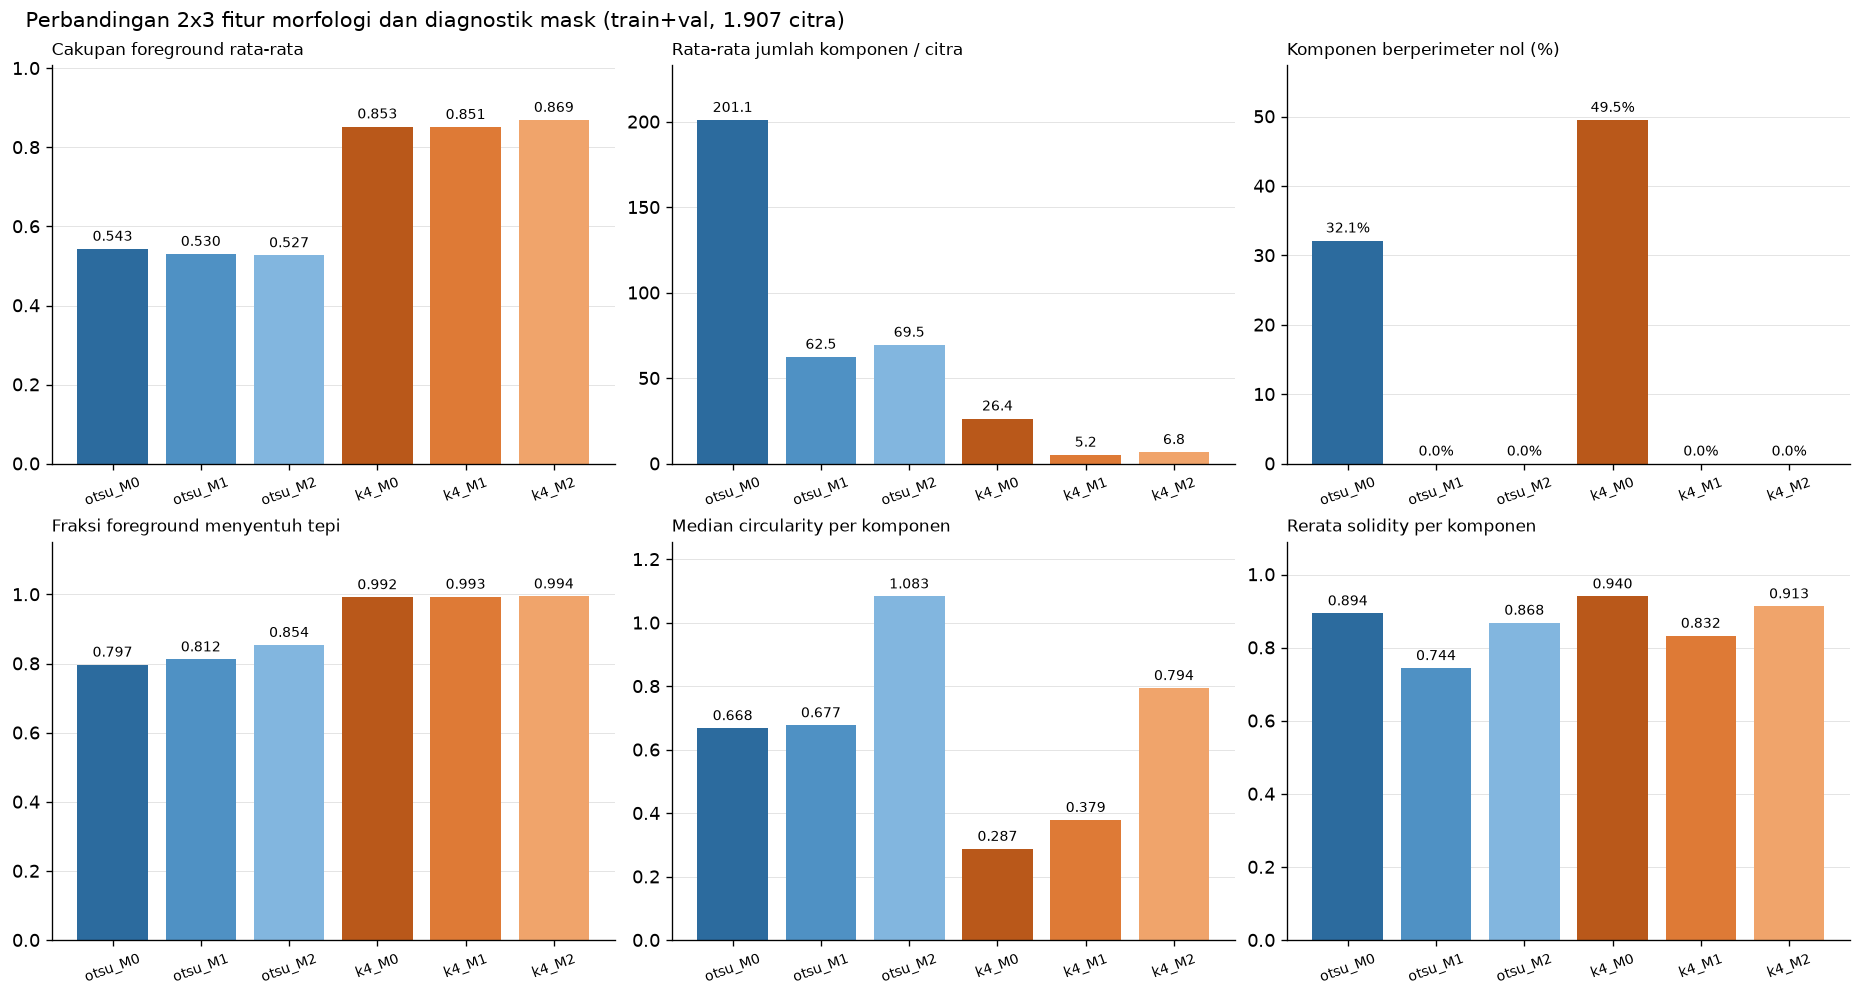

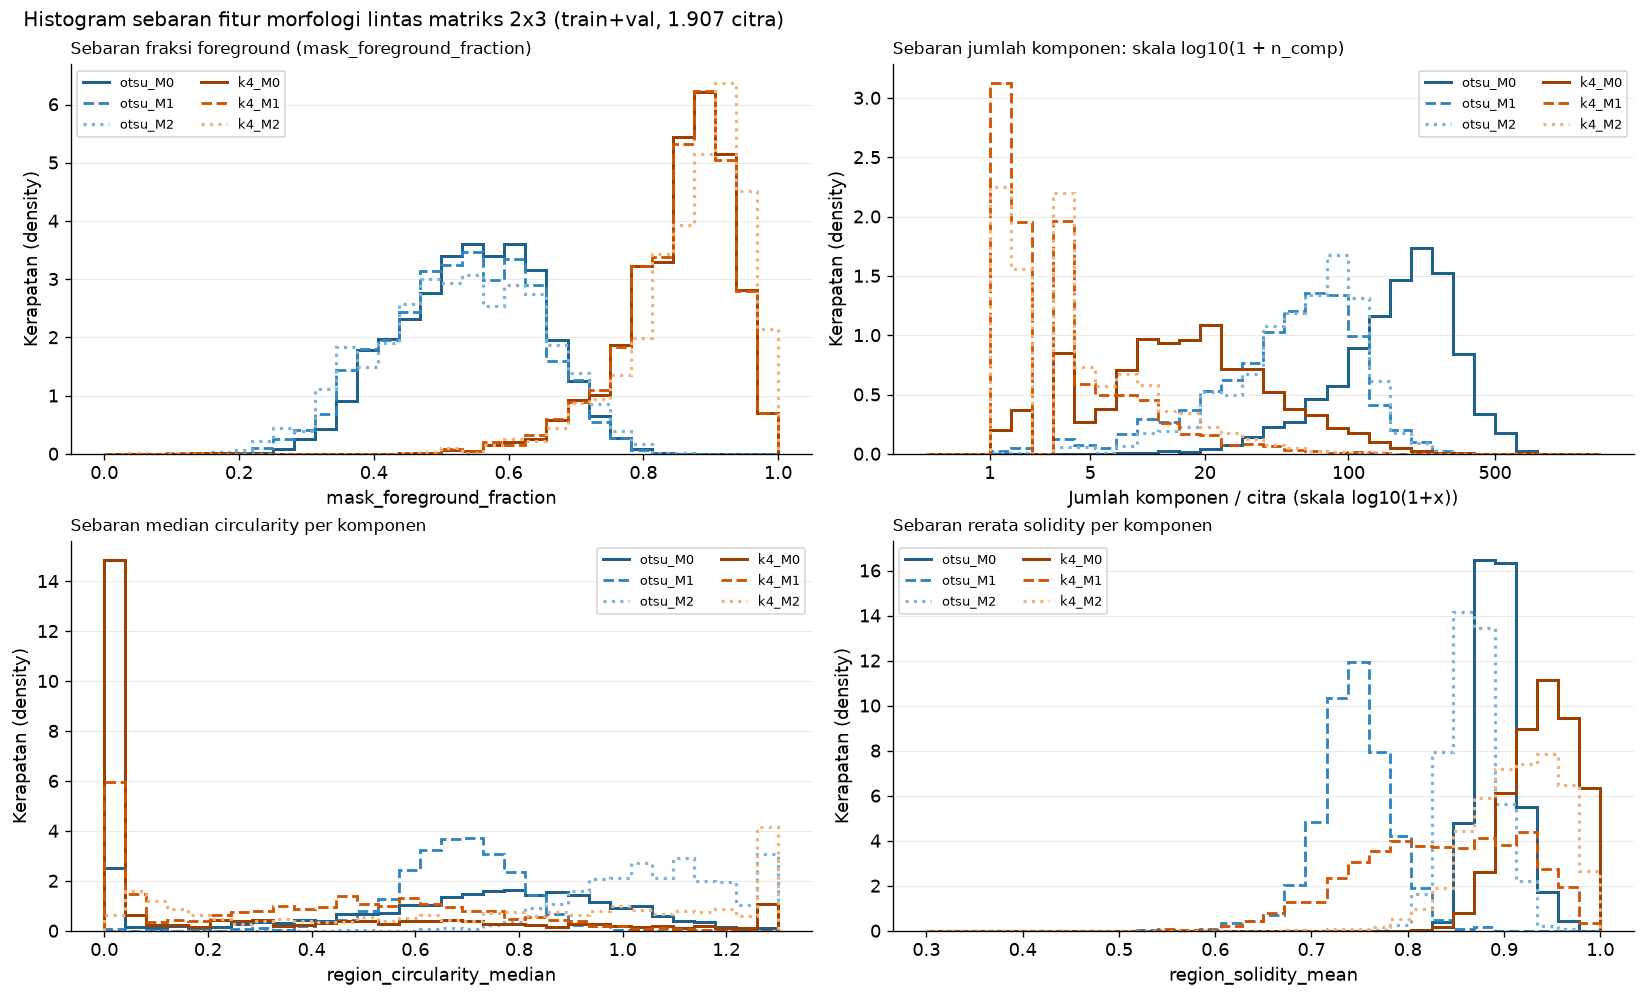

In [5]:
feature_summary_2x3 = pd.DataFrame(
    {
        method: combined_tv[method][
            [
                "mask_foreground_fraction",
                "mask_component_count",
                "mask_edge_foreground_fraction",
                "region_area_rel_median",
                "region_circularity_median",
                "region_solidity_mean",
                "region_eccentricity_median",
            ]
        ].mean()
        for method in FEATURE_METHODS
    }
).T

diag_summary_2x3 = diagnostics_tv.groupby("method", observed=True).agg(
    empty_masks=("is_empty", "sum"),
    zero_perimeter_components=("zero_perimeter_count", "sum"),
    total_components=("component_count", "sum"),
    border_components=("border_component_count", "sum"),
)
diag_summary_2x3["zero_perimeter_pct"] = (
    100.0 * diag_summary_2x3["zero_perimeter_components"] / diag_summary_2x3["total_components"].replace(0, np.nan)
)

table_2x3 = pd.concat(
    [
        summary.loc[list(FEATURE_METHODS), ["mean_category_dice", "mean_category_iou"]],
        feature_summary_2x3,
        diag_summary_2x3,
    ],
    axis=1,
).loc[list(FEATURE_METHODS)]
table_2x3.insert(0, "keluarga", [m.split("_", 1)[0] for m in table_2x3.index])
table_2x3.insert(1, "tahap", [m.split("_", 1)[1] for m in table_2x3.index])

display(
    table_2x3.style.format(
        {
            "mean_category_dice": "{:.4f}",
            "mean_category_iou": "{:.4f}",
            "mask_foreground_fraction": "{:.4f}",
            "mask_component_count": "{:.1f}",
            "mask_edge_foreground_fraction": "{:.4f}",
            "region_area_rel_median": "{:.4f}",
            "region_circularity_median": "{:.4f}",
            "region_solidity_mean": "{:.4f}",
            "region_eccentricity_median": "{:.4f}",
            "zero_perimeter_pct": "{:.2f}%",
        }
    )
)

fig_2x3, axes_2x3 = plt.subplots(2, 3, figsize=(15.4, 8.2), layout="constrained")
metrics_plot = [
    ("mask_foreground_fraction", "Cakupan foreground rata-rata", "{:.3f}"),
    ("mask_component_count", "Rata-rata jumlah komponen / citra", "{:.1f}"),
    ("zero_perimeter_pct", "Komponen berperimeter nol (%)", "{:.1f}%"),
    ("mask_edge_foreground_fraction", "Fraksi foreground menyentuh tepi", "{:.3f}"),
    ("region_circularity_median", "Median circularity per komponen", "{:.3f}"),
    ("region_solidity_mean", "Rerata solidity per komponen", "{:.3f}"),
]
colors_2x3 = ["#2C6B9E", "#4F91C4", "#82B6DF", "#B9581A", "#DE7A36", "#F0A46B"]

for axis, (col, title, fmt) in zip(axes_2x3.ravel(), metrics_plot):
    vals = table_2x3[col].to_numpy(dtype=float)
    bars = axis.bar(list(FEATURE_METHODS), vals, color=colors_2x3)
    top_pad = 0.04 * max(float(vals.max()), 1e-9)
    for bar, v in zip(bars, vals):
        axis.text(
            bar.get_x() + bar.get_width() / 2.0,
            v + top_pad * 0.35,
            fmt.format(v),
            ha="center",
            va="bottom",
            fontsize=8.2,
        )
    axis.set_ylim(0.0, max(float(vals.max()) + 4.0 * top_pad, 1e-6))
    axis.set_title(title, loc="left", fontsize=10)
    axis.tick_params(axis="x", rotation=20, labelsize=8.5)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)

fig_2x3.suptitle(
    "Perbandingan 2x3 fitur morfologi dan diagnostik mask (train+val, 1.907 citra)",
    fontsize=12.5,
    x=0.01,
    ha="left",
)
finish_figure(
    fig_2x3,
    export_path=(ROOT / "reports/figures/06_feature_sensitivity_2x3.png") if EXPORT_FIGURES else None,
)

# 2x2 histogram distributions comparing morphology features across all 6 configurations (train+val)
fig_mh, axes_mh = plt.subplots(2, 2, figsize=(13.6, 8.2), layout="constrained")
hist_specs = [
    ("mask_foreground_fraction", "Sebaran fraksi foreground (mask_foreground_fraction)", np.linspace(0.0, 1.0, 33), False),
    ("mask_component_count", "Sebaran jumlah komponen: skala log10(1 + n_comp)", np.linspace(0.0, 3.2, 33), True),
    ("region_circularity_median", "Sebaran median circularity per komponen", np.linspace(0.0, 1.3, 33), False),
    ("region_solidity_mean", "Sebaran rerata solidity per komponen", np.linspace(0.3, 1.0, 33), False),
]
style_map = {
    "otsu_M0": ("#1F618D", "-", 1.8),
    "otsu_M1": ("#2E86C1", "--", 1.7),
    "otsu_M2": ("#7FB3D5", ":", 1.9),
    "k4_M0": ("#A04000", "-", 1.8),
    "k4_M1": ("#D35400", "--", 1.7),
    "k4_M2": ("#F0B27A", ":", 1.9),
}
for ax, (col, title, edges, use_log1p) in zip(axes_mh.ravel(), hist_specs):
    for m_name in FEATURE_METHODS:
        arr = combined_tv[m_name][col].to_numpy(dtype=float)
        vals = np.log10(1.0 + np.clip(arr, 0.0, None)) if use_log1p else arr
        counts, _ = np.histogram(np.clip(vals, edges[0], edges[-1]), bins=edges, density=True)
        col_hex, ls, lw = style_map[m_name]
        ax.stairs(counts, edges, color=col_hex, linestyle=ls, linewidth=lw, label=m_name)
    if use_log1p:
        ticks_raw = [1, 5, 20, 100, 500]
        ax.set_xticks([np.log10(1.0 + t) for t in ticks_raw], [str(t) for t in ticks_raw])
        ax.set_xlabel("Jumlah komponen / citra (skala log10(1+x))")
    else:
        ax.set_xlabel(col)
    ax.set_ylabel("Kerapatan (density)")
    ax.set_title(title, loc="left", fontsize=10.0)
    ax.grid(axis="y", color="#EAEAEA", linewidth=0.6)
    ax.legend(frameon=True, fontsize=8.0, ncol=2, loc="best")

fig_mh.suptitle(
    "Histogram sebaran fitur morfologi lintas matriks 2x3 (train+val, 1.907 citra)",
    fontsize=12.0,
    x=0.01,
    ha="left",
)
finish_figure(
    fig_mh,
    export_path=(ROOT / "reports/figures/06_morphology_feature_histograms_2x3.png") if EXPORT_FIGURES else None,
)


### Temuan 2 — perbedaan struktur morfologi 2×3: *Otsu* vs *K-Means k=4* dan efek `M0 → M1 → M2`

- **Kontras antar-keluarga (`otsu` vs `k4`):**
  - Seluruh konfigurasi **`k4`** menutup **85,1%–86,9%** luas bidang citra (`mask_edge_foreground_fraction` **0,9918–0,9941**), dengan sangat sedikit komponen terpisah (**26,4** pada `k4_M0`, turun menjadi **5,2** pada `k4_M1` dan **6,8** pada `k4_M2`) serta median area komponen mencapai **37,2% (`k4_M1`)** hingga **28,3% (`k4_M2`)** dari total luas citra. Akibat penggabungan epitel dan stroma ke dalam satu lembaran besar, perbedaan bentuk kelenjar antar-kelas menjadi teredam meski skor *Dice overlap* terhadap *ground truth* tinggi (`0,775–0,776`).
  - Sebaliknya, **`otsu`** hanya menandai piksel epitel/nukleus gelap (**52,7%–54,3%** luas citra), menghasilkan **62,5–201,1 komponen terpisah per citra** dengan median luas komponen sangat halus (**0,0001–0,0047** luas citra).
- **Efek tahap morfologi (`M0` $\rightarrow$ `M1` $\rightarrow$ `M2`):**
  - **`M0` $\rightarrow$ `M1` (`area >= 16 px`):** menihilkan komponen berperimeter nol (`32,13%` pada `otsu_M0` dan `49,50%` pada `k4_M0` menjadi `0,00%`), memangkas rerata jumlah komponen tajam (`201,1 -> 62,5` pada Otsu; `26,4 -> 5,2` pada K-means), dan menurunkan `solidity` (`0,8935 -> 0,7439` pada Otsu; `0,9399 -> 0,8321` pada K-means) karena hanya komponen berongga/berlekuk lebih besar yang tersisa.
  - **`M1` $\rightarrow$ `M2` (*opening + closing* $3\times 3$):** memperhalus kontur dan menutup celah internal kecil (`region_circularity_median` melonjak `0,6769 -> 1,0830` pada Otsu dan `0,3785 -> 0,7941` pada K-means; `solidity` kembali naik ke `0,8678` dan `0,9128`). Konsekuensinya perlu diuji pada tahap 07 untuk mengetahui apakah peluruhan detail nukleus `M0 -> M1 -> M2` membantu atau justru mengurangi daya pisah klasifikasi.


## 5. Statistik deskriptif per kategori, pergeseran `A → A_seg`, dan sebaran fitur (`train` + `val`)

Tabel dan *boxplot* berikut disusun dari subset **`train` + `val` (`1.907` citra)**; nilai asosiasi univariat `eta^2` dihitung khusus pada **`train` (`1.535` citra)** agar eksplorasi fitur tidak menyentuh `test` maupun *model selection*.


,lab_l_mean,lab_a_mean,lab_b_mean,glcm_contrast,glcm_homogeneity,mask_foreground_fraction,mask_component_count,region_circularity_median,region_eccentricity_median,region_solidity_median
category,,,,,,,,,,
Adenocarcinoma,47.4130,38.1496,-41.4494,6.7214,0.4786,0.8590,17.8554,0.4115,0.6168,0.9785
High-grade IN,46.6207,38.3737,-42.1581,5.6040,0.5124,0.8519,18.2781,0.3192,0.6175,0.9792
Low-grade IN,45.6023,36.8771,-37.6285,6.3239,0.4826,0.8633,25.0436,0.2527,0.5450,0.9920
Normal,50.7641,31.0281,-34.4294,6.4108,0.4810,0.7895,63.4375,0.2023,0.5279,0.9928
Polyp,43.7031,29.9714,-32.6071,5.7919,0.5014,0.8429,39.2476,0.1472,0.4081,0.9933
Serrated adenoma,45.1208,27.5232,-26.9500,4.9008,0.5206,0.8149,25.3000,0.1988,0.5957,0.9904


,otsu_M0_fg,otsu_M0_comp,otsu_M2_comp,k4_M0_fg,k4_M0_comp,k4_M2_comp
category,,,,,,
Adenocarcinoma,0.563,201.444,70.036,0.859,17.855,5.113
High-grade IN,0.644,113.437,35.278,0.852,18.278,5.325
Low-grade IN,0.558,195.570,64.534,0.863,25.044,5.583
Normal,0.431,250.266,82.047,0.789,63.438,14.875
Polyp,0.463,242.802,89.340,0.843,39.248,10.352
Serrated adenoma,0.619,107.820,38.820,0.815,25.300,5.800


,fitur,mean_A_tv,mean_A_seg_tv,delta,relative_delta
0,lab_l_mean,46.0624,39.8934,-6.1690,-13.39%
1,lab_l_std,21.6849,17.0564,-4.6284,-21.34%
2,lab_a_mean,35.4809,40.3149,+4.8340,+13.62%
3,lab_a_std,14.0791,7.9870,-6.0921,-43.27%
4,lab_b_mean,-37.8383,-42.9072,-5.0689,-13.40%
5,lab_b_std,15.5259,10.2652,-5.2607,-33.88%
6,glcm_contrast,6.2552,5.3440,-0.9112,-14.57%
7,glcm_homogeneity,0.4887,0.4839,-0.0048,-0.98%
8,glcm_energy,0.1346,0.1399,+0.0053,+3.96%
9,glcm_correlation,0.7473,0.6531,-0.0942,-12.60%


,A,A_seg,delta
lab_b_std,0.1549,0.0580,-0.0969
lab_b_mean,0.1384,0.1671,0.0287
lab_a_mean,0.1226,0.1443,0.0217
lab_l_mean,0.1194,0.0746,-0.0448
glcm_homogeneity,0.0534,0.0618,0.0084
glcm_contrast,0.0534,0.0497,-0.0037
lab_a_std,0.0517,0.0877,0.0361
glcm_correlation,0.0368,0.0679,0.0311
glcm_energy,0.0297,0.0333,0.0036
lab_l_std,0.0196,0.0608,0.0412


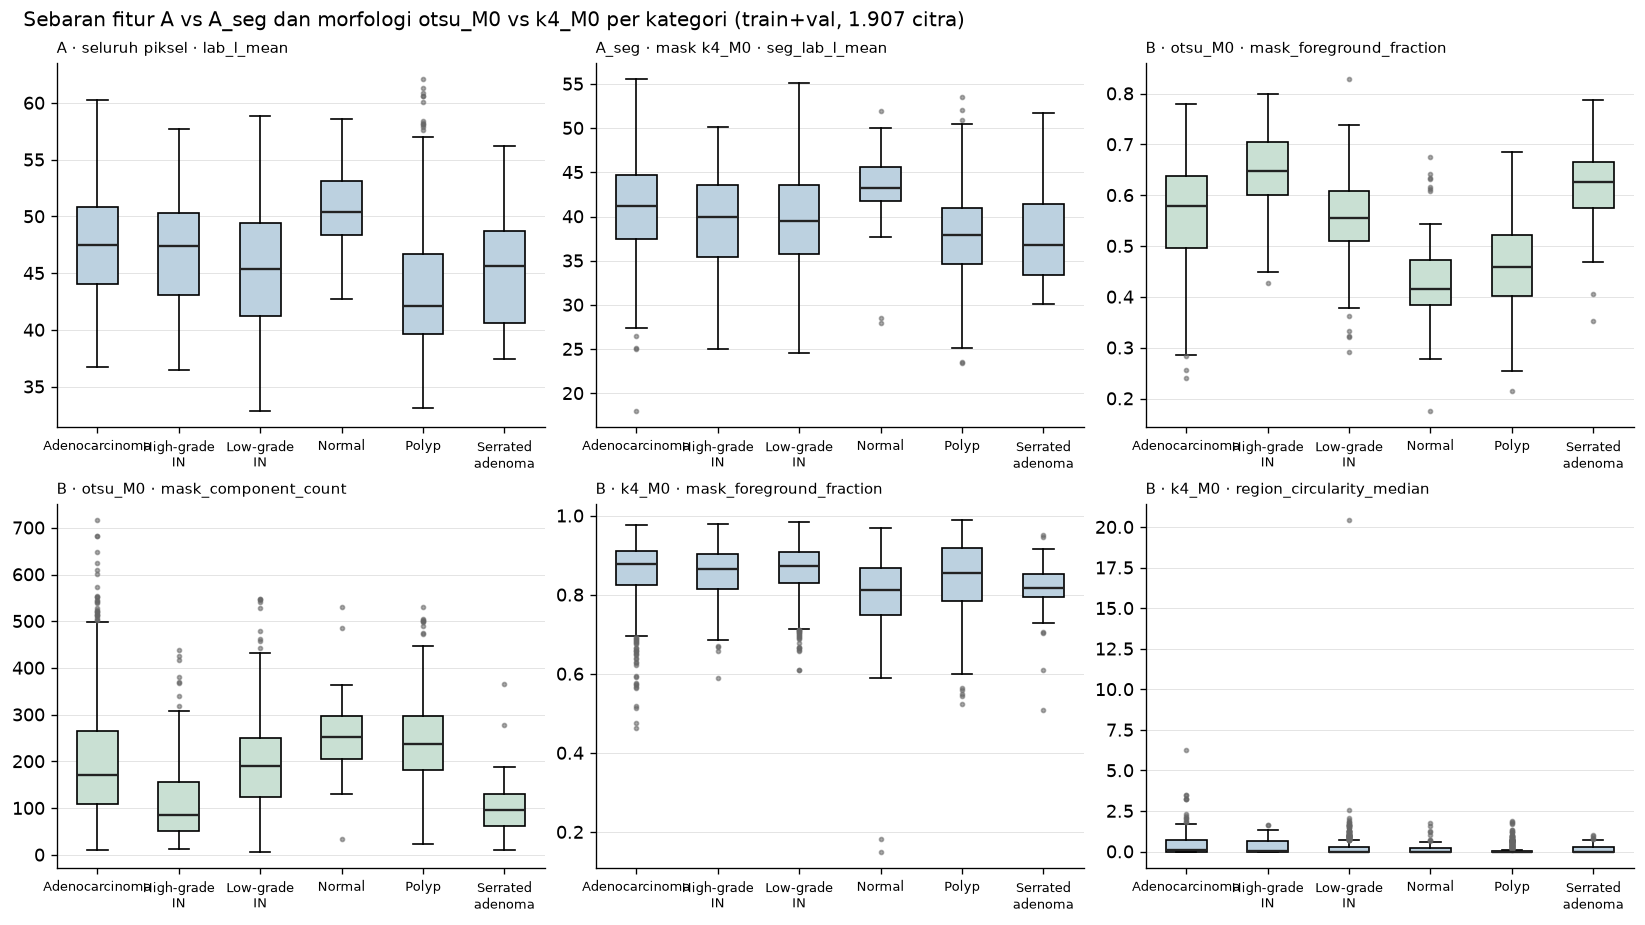

In [6]:
primary_tv = combined_tv[PRIMARY_METHOD]
assert len(primary_tv) == len(segmented_tv) == len(appearance_tv)

display_columns = [
    "lab_l_mean",
    "lab_a_mean",
    "lab_b_mean",
    "glcm_contrast",
    "glcm_homogeneity",
    "mask_foreground_fraction",
    "mask_component_count",
    "region_circularity_median",
    "region_eccentricity_median",
    "region_solidity_median",
]
category_means_tv = (
    primary_tv.groupby("category", observed=True)[list(FEATURE_NAMES)]
    .mean()
    .reindex(list(EXPECTED_CATEGORIES))
)
display(category_means_tv[display_columns].style.format("{:.4f}"))

# Compare morphology category means on otsu_M0 vs k4_M0 (train+val)
morph_compare = pd.DataFrame(
    {
        "otsu_M0_fg": combined_tv["otsu_M0"].groupby("category", observed=True)["mask_foreground_fraction"].mean(),
        "otsu_M0_comp": combined_tv["otsu_M0"].groupby("category", observed=True)["mask_component_count"].mean(),
        "otsu_M2_comp": combined_tv["otsu_M2"].groupby("category", observed=True)["mask_component_count"].mean(),
        "k4_M0_fg": combined_tv["k4_M0"].groupby("category", observed=True)["mask_foreground_fraction"].mean(),
        "k4_M0_comp": combined_tv["k4_M0"].groupby("category", observed=True)["mask_component_count"].mean(),
        "k4_M2_comp": combined_tv["k4_M2"].groupby("category", observed=True)["mask_component_count"].mean(),
    }
).reindex(list(EXPECTED_CATEGORIES))
display(morph_compare.style.format("{:.3f}"))

w_mat = primary_tv[list(APPEARANCE_FEATURE_NAMES)]
s_mat = segmented_tv[[f"seg_{name}" for name in APPEARANCE_FEATURE_NAMES]]
appearance_comparison = pd.DataFrame(
    {
        "fitur": list(APPEARANCE_FEATURE_NAMES),
        "mean_A_tv": w_mat.mean().to_numpy(),
        "mean_A_seg_tv": s_mat.mean().to_numpy(),
    }
)
appearance_comparison["delta"] = appearance_comparison["mean_A_seg_tv"] - appearance_comparison["mean_A_tv"]
appearance_comparison["relative_delta"] = appearance_comparison["delta"] / appearance_comparison["mean_A_tv"].abs().clip(lower=1e-12)
display(
    appearance_comparison.style.format(
        {"mean_A_tv": "{:.4f}", "mean_A_seg_tv": "{:.4f}", "delta": "{:+.4f}", "relative_delta": "{:+.2%}"}
    )
)

def eta_squared(frame: pd.DataFrame, features: list[str]) -> pd.Series:
    overall_mean = frame[features].mean()
    group_mean = frame.groupby("category", observed=True)[features].mean()
    group_n = frame.groupby("category", observed=True).size()
    between = ((group_mean - overall_mean) ** 2).mul(group_n, axis=0).sum()
    total = (frame[features] - overall_mean).pow(2).sum()
    return between / total.replace(0.0, np.nan)

eta_whole = eta_squared(primary_tv.loc[primary_tv["split"].eq("train")], list(APPEARANCE_FEATURE_NAMES))
eta_seg = eta_squared(
    segmented_tv.loc[segmented_tv["split"].eq("train")],
    [f"seg_{name}" for name in APPEARANCE_FEATURE_NAMES],
)
eta_seg.index = list(APPEARANCE_FEATURE_NAMES)
eta_table = pd.DataFrame({"A": eta_whole, "A_seg": eta_seg})
eta_table["delta"] = eta_table["A_seg"] - eta_table["A"]
display(eta_table.sort_values("A", ascending=False).style.format("{:.4f}"))

# Plot distributions comparing Set A, A_seg, Otsu_M0 morphology, and k4_M0 morphology on train+val
plot_panels = [
    ("A · seluruh piksel", primary_tv, "lab_l_mean"),
    ("A_seg · mask " + SEGMENTED_METHOD, segmented_tv, "seg_lab_l_mean"),
    ("B · otsu_M0", combined_tv["otsu_M0"], "mask_foreground_fraction"),
    ("B · otsu_M0", combined_tv["otsu_M0"], "mask_component_count"),
    ("B · k4_M0", primary_tv, "mask_foreground_fraction"),
    ("B · k4_M0", primary_tv, "region_circularity_median"),
]

fig, axes = plt.subplots(2, 3, figsize=(13.6, 7.6), layout="constrained")
for axis, (panel_label, frame, feature_name) in zip(axes.ravel(), plot_panels):
    values = [
        frame.loc[frame["category"].eq(category), feature_name].to_numpy()
        for category in EXPECTED_CATEGORIES
    ]
    boxplot = axis.boxplot(
        values,
        tick_labels=[category.replace(" ", "\n") for category in EXPECTED_CATEGORIES],
        patch_artist=True,
        medianprops={"color": "#222222", "linewidth": 1.4},
        flierprops={
            "marker": "o",
            "markersize": 2.4,
            "markerfacecolor": "#666666",
            "markeredgecolor": "#666666",
            "alpha": 0.55,
        },
    )
    box_color = "#C9E0D3" if "otsu" in panel_label else "#BCD1E0"
    for patch in boxplot["boxes"]:
        patch.set_facecolor(box_color)
    axis.set_title(f"{panel_label} · {feature_name}", loc="left", fontsize=9.2)
    axis.grid(axis="y", color="#E4E4E4", linewidth=0.6)
    axis.tick_params(axis="x", labelsize=7.6)

fig.suptitle(
    "Sebaran fitur A vs A_seg dan morfologi otsu_M0 vs k4_M0 per kategori (train+val, 1.907 citra)",
    fontsize=12,
    x=0.01,
    ha="left",
)
finish_figure(
    fig,
    export_path=(ROOT / "reports/figures/06_feature_distributions_by_category.png") if EXPORT_FIGURES else None,
)


### Temuan 3 — kontras per kategori (`otsu` vs `k4`) dan pergeseran `A → A_seg`

- Pada `train+val`, perbedaan jumlah komponen terpisah pada `otsu_M0` mencolok antar-kategori (misalnya *Polyp* dan *Low-grade IN* vs *Adenocarcinoma*), sedangkan pada `k4_M0` sebaran `mask_foreground_fraction` cenderung mengumpul tinggi (`0,80–0,95`) di seluruh kategori.
- Pemasking `A -> A_seg` pada `k4_M0` menurunkan `L*` rerata **13,39%**, menaikkan `a*` **13,62%**, menurunkan `b*` **13,40%**, serta memangkas simpangan baku warna hingga **−43,27%** (`lab_a_std`). Rata-rata $\eta^2$ *train* hanya berubah tipis (`0,0805` vs `0,0780`), sehingga nilai tambahnya wajib diuji langsung melalui klasifikasi SVM pada Tahap 07.


## 6. Korelasi antar fitur pada Set C dan perbandingan `otsu_M0` vs `k4_M0` (`train` + `val`)

Sel ini memeriksa redundansi antar 29 fitur pada `train+val` untuk `k4_M0` (dibanding `C_seg`) dan `otsu_M0`, serta stabilitas korelasi berpasangan fitur A dengan `A_seg`.


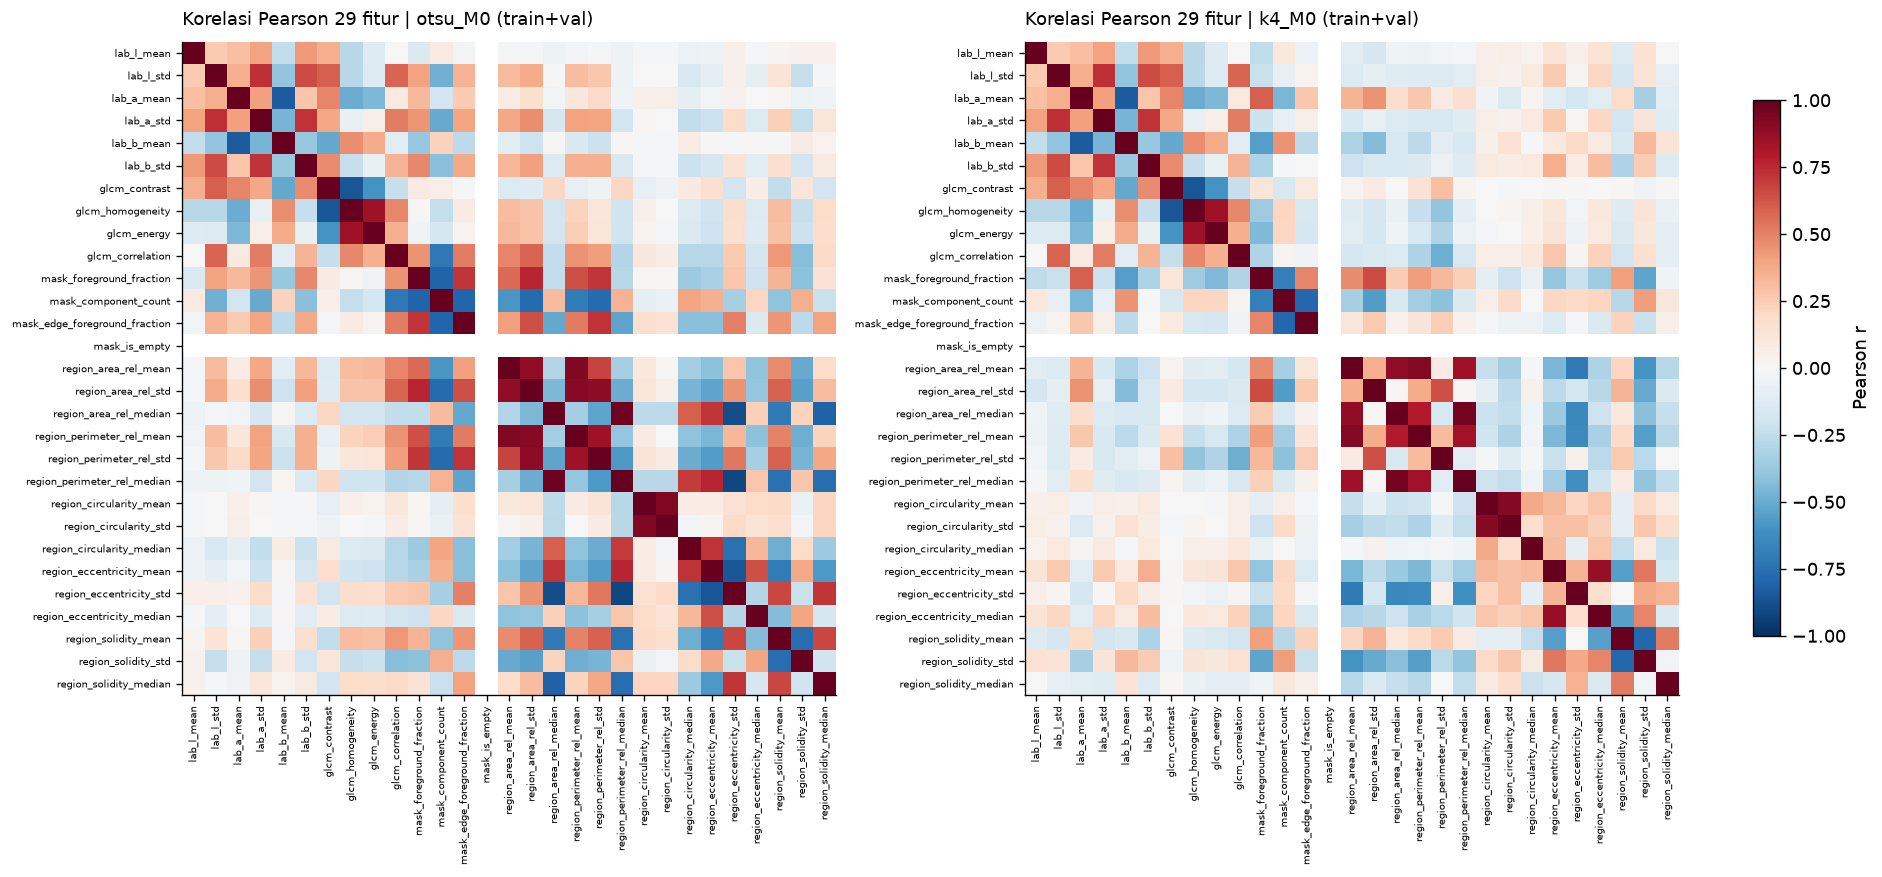

,feature_1,feature_2,r
0,region_area_rel_median,region_perimeter_rel_median,+0.9533
1,region_circularity_mean,region_circularity_std,+0.9186
2,region_area_rel_mean,region_perimeter_rel_mean,+0.9162
3,region_area_rel_mean,region_area_rel_median,+0.8880
4,region_eccentricity_mean,region_eccentricity_median,+0.8678
5,glcm_contrast,glcm_homogeneity,-0.8559
6,glcm_homogeneity,glcm_energy,+0.8503
7,region_area_rel_mean,region_perimeter_rel_median,+0.8471


,feature_1,feature_2,r
0,region_area_rel_median,region_perimeter_rel_median,+0.9707
1,region_area_rel_mean,region_perimeter_rel_mean,+0.9285
2,region_circularity_mean,region_circularity_std,+0.9282
3,region_area_rel_std,region_perimeter_rel_mean,+0.9140
4,region_perimeter_rel_median,region_eccentricity_std,-0.9075
5,region_area_rel_std,region_perimeter_rel_std,+0.8920
6,region_area_rel_median,region_eccentricity_std,-0.8873
7,region_area_rel_mean,region_area_rel_std,+0.8865


,fitur,r_A_A_seg
4,lab_b_mean,+0.9699
2,lab_a_mean,+0.9679
6,glcm_contrast,+0.9488
7,glcm_homogeneity,+0.8597
0,lab_l_mean,+0.7872
1,lab_l_std,+0.7501
5,lab_b_std,+0.6836
8,glcm_energy,+0.6579
9,glcm_correlation,+0.6219
3,lab_a_std,+0.5320


Pasangan |r| >= 0.8 (train+val): otsu_M0 C=15 | k4_M0 C=10 | C_seg=11.


In [7]:
correlation = primary_tv[list(FEATURE_NAMES)].corr(method="pearson")
correlation_otsu = combined_tv["otsu_M0"][list(FEATURE_NAMES)].corr(method="pearson")
segmented_correlation = segmented_tv[list(SEGMENTED_FEATURE_NAMES)].corr(method="pearson")

fig_corr, axes_corr = plt.subplots(1, 2, figsize=(15.6, 7.2), layout="constrained")
for ax, corr_mat, title in zip(
    axes_corr,
    [correlation_otsu, correlation],
    ["Korelasi Pearson 29 fitur | otsu_M0 (train+val)", f"Korelasi Pearson 29 fitur | {PRIMARY_METHOD} (train+val)"],
):
    im = ax.imshow(corr_mat.to_numpy(), cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")
    positions = np.arange(len(FEATURE_NAMES))
    ax.set_xticks(positions, FEATURE_NAMES, rotation=90, fontsize=6.0)
    ax.set_yticks(positions, FEATURE_NAMES, fontsize=6.0)
    ax.set_title(title, loc="left", fontsize=10.5, pad=10)
fig_corr.colorbar(im, ax=axes_corr, shrink=0.82, label="Pearson r")
finish_figure(
    fig_corr,
    export_path=(ROOT / "reports/figures/06_feature_correlation_heatmap.png") if EXPORT_FIGURES else None,
)

def high_correlation_pairs(matrix: pd.DataFrame, threshold: float = 0.8) -> pd.DataFrame:
    rows, cols = np.triu_indices(len(matrix), k=1)
    pairs = pd.DataFrame(
        {
            "feature_1": matrix.index.to_numpy()[rows],
            "feature_2": matrix.columns.to_numpy()[cols],
            "r": matrix.to_numpy()[rows, cols],
        }
    )
    return pairs.loc[pairs["r"].abs().ge(threshold)].sort_values(
        "r", key=lambda series: series.abs(), ascending=False
    ).reset_index(drop=True)

high_pairs_k4 = high_correlation_pairs(correlation)
high_pairs_otsu = high_correlation_pairs(correlation_otsu)
high_pairs_segmented = high_correlation_pairs(segmented_correlation)
matched_correlation = pd.DataFrame(
    {
        "fitur": list(APPEARANCE_FEATURE_NAMES),
        "r_A_A_seg": [
            primary_tv[name].corr(segmented_tv[f"seg_{name}"])
            for name in APPEARANCE_FEATURE_NAMES
        ],
    }
).sort_values("r_A_A_seg", ascending=False)

display(high_pairs_k4.head(8).style.format({"r": "{:+.4f}"}))
display(high_pairs_otsu.head(8).style.format({"r": "{:+.4f}"}))
display(matched_correlation.style.format({"r_A_A_seg": "{:+.4f}"}))
print(
    f"Pasangan |r| >= 0.8 (train+val): otsu_M0 C={len(high_pairs_otsu)} | {PRIMARY_METHOD} C={len(high_pairs_k4)} | "
    f"C_seg={len(high_pairs_segmented)}."
)


## 7. Uji paritas reproduksi langsung dari citra RGB untuk semua 6 konfigurasi 2×3

Sel ini menghitung ulang fitur langsung dari citra RGB asli (konfigurasi Otsu/K-means beku + aturan morfologi `M0`/`M1`/`M2`) pada sampel `train` dan `val` untuk keenam konfigurasi 2×3 maupun `A_seg`/`C_seg` `k4_M0`, lalu membuktikan kesamaan hingga presisi mesin (`< 1e-12`) tanpa membaca label kategori `test`.


In [8]:
parity_ids = []
for split_name in ("train", "val"):
    parity_ids.extend(
        split_tv.loc[split_tv["split"].eq(split_name), "sample_id"]
        .head(PARITY_SAMPLES_PER_DEV_SPLIT)
        .tolist()
    )

parity_tables = build_feature_tables(
    ROOT,
    methods=FEATURE_METHODS,
    splits=("train", "val"),
    data_root_override=DATA_ROOT_OVERRIDE,
    sample_ids=parity_ids,
)
validate_feature_table(parity_tables.appearance, feature_names=APPEARANCE_FEATURE_NAMES, require_method=False)

parity_rows = []
for method in FEATURE_METHODS:
    stored = combined_tv[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    recomputed = parity_tables.combined[method].set_index("sample_id").loc[parity_ids, list(FEATURE_NAMES)]
    max_abs_diff = float(np.abs(stored.to_numpy() - recomputed.to_numpy()).max())
    parity_rows.append(
        {"method": method, "n_samples": len(parity_ids), "max_abs_difference": max_abs_diff}
    )

parity_report = pd.DataFrame(parity_rows)
display(parity_report.style.format({"max_abs_difference": "{:.3e}"}))
assert parity_report["max_abs_difference"].max() < 1e-12

segmented_parity_tables = build_segmented_feature_tables(
    ROOT,
    method=SEGMENTED_METHOD,
    splits=("train", "val"),
    data_root_override=DATA_ROOT_OVERRIDE,
    sample_ids=parity_ids,
)
segmented_stored = segmented_tv.set_index("sample_id").loc[parity_ids, list(SEGMENTED_FEATURE_NAMES)]
segmented_recomputed = segmented_parity_tables.combined.set_index("sample_id").loc[parity_ids, list(SEGMENTED_FEATURE_NAMES)]
seg_diff = float(np.abs(segmented_stored.to_numpy() - segmented_recomputed.to_numpy()).max())
assert seg_diff < 1e-12
print(f"Paritas 6 konfigurasi 2x3 + A_seg/C_seg terverifikasi (< 1e-12; max_seg_diff={seg_diff:.3e}).")


,method,n_samples,max_abs_difference
0,otsu_M0,6,0.000e+00
1,otsu_M1,6,0.000e+00
2,otsu_M2,6,0.000e+00
3,k4_M0,6,0.000e+00
4,k4_M1,6,0.000e+00
5,k4_M2,6,0.000e+00


Paritas 6 konfigurasi 2x3 + A_seg/C_seg terverifikasi (< 1e-12; max_seg_diff=0.000e+00).


## 8. Inventaris artefak, konservasi v1, kontrak *upstream*, dan serah-terima ke tahap 07

- **Tabel fitur lengkap 2×3 (`2.226` citra $\times$ 6 konfigurasi)** tersedia di `results/features/features_<method>.csv`, disertai `feature_manifest_2x3.json` dan `morphology_diagnostics_2x3.csv`.
- **Artefak v1 terjaga penuh:** `appearance.csv`, keempat tabel `features_{otsu_M0,otsu_M2,k4_M0,k4_M1}.csv`, `feature_manifest.json`, `morphology_diagnostics.csv`, serta `A_seg`/`C_seg` `k4_M0` tetap *byte-identical*.
- **Serah-terima berdisiplin kebocoran ke Tahap 07:** notebook berikutnya (`07_svm_classification.ipynb`) membandingkan `v2` (evaluasi CV *fixed-upstream* menggunakan tabel fitur ini) terhadap protokol ketat **`v3` (`2x3-strict`)** yang me-*refit* polaritas Otsu dan klastering/pemetaan terawasi `k4` di dalam tiap fold latih *5-fold StratifiedGroupKFold* (`results/classification_2x3_strict/fold_upstream_audit.json`), dengan grid hiperparameter *validation-blind* sebelum evaluasi tunggal pada `val`.


In [9]:
# Ringkasan parameter upstream beku (train-full) dan audit ketat tahap 07 bila tersedia
otsu_cfg = json.loads(protected_files["otsu_config"].read_text(encoding="utf-8"))
k4_cfg = json.loads((ROOT / "models/kmeans_lab_k4_mapped.json").read_text(encoding="utf-8"))
upstream_audit_path = ROOT / "results/classification_2x3_strict/fold_upstream_audit.json"

upstream_rows = [
    {
        "komponen_upstream": "Otsu global foreground polarity",
        "artefak_latih_penuh": "configs/otsu_raw.json",
        "dependensi_data_latih": f"Supervised {otsu_cfg['selection_metric']} pada mask ground truth {otsu_cfg['polarity_selected_on']}",
        "ringkasan": f"polarity={otsu_cfg['foreground_polarity']} (train {otsu_cfg['selection_metric']}={otsu_cfg['training_mean_category_dice']:.4f})",
    },
    {
        "komponen_upstream": "Lab K-Means (k=4) + supervised cluster mapping",
        "artefak_latih_penuh": "models/kmeans_lab_k4_mapped.json",
        "dependensi_data_latih": (
            f"Unsupervised sampling train (seed={k4_cfg['sampling']['seed']}, "
            f"{k4_cfg['sampling']['pixels_per_image']} px/img) + "
            f"supervised rate>={k4_cfg['foreground_mapping']['threshold']:.2f}"
        ),
        "ringkasan": (
            f"fg_clusters={k4_cfg['foreground_clusters']} | "
            f"rates={[round(float(r), 4) for r in k4_cfg['foreground_mapping']['cluster_reference_foreground_rates']]}"
        ),
    },
]
if upstream_audit_path.is_file():
    u_audit = json.loads(upstream_audit_path.read_text(encoding="utf-8"))
    upstream_rows.append(
        {
            "komponen_upstream": "Verifikasi fold-aware 5-fold CV (Tahap 07 v3)",
            "artefak_latih_penuh": "results/classification_2x3_strict/fold_upstream_audit.json",
            "dependensi_data_latih": "Refit Otsu polarity & Lab K-Means + mapping hanya memakai fold-train",
            "ringkasan": (
                f"otsu_all_dark={u_audit['otsu_fold_invariance_all_dark']} | "
                f"k4_center_L2_range=[{min(u_audit['k4_fold_mean_center_l2_vs_full_train']):.2f}, "
                f"{max(u_audit['k4_fold_mean_center_l2_vs_full_train']):.2f}] | "
                f"k4_M0_IoU_min={min(u_audit['k4_m0_fold_val_iou_vs_full_train_means']):.4f}"
            ),
        }
    )
display(pd.DataFrame(upstream_rows))

artifact_inventory = pd.DataFrame(
    [
        {
            "artefak": path.relative_to(ROOT).as_posix(),
            "bytes": path.stat().st_size,
            "sha256_prefix": input_hashes_before[name][:20],
        }
        for name, path in protected_files.items()
    ]
)
display(artifact_inventory)

input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak input berubah saat notebook dieksekusi."
assert set(manifest_2x3["methods"]) == set(FEATURE_METHODS)
print(
    f"Selesai: 6 konfigurasi 2x3 ({', '.join(FEATURE_METHODS)}) + Set A bersama terverifikasi; "
    "seluruh artefak input v1 & v2 tetap identik; 0 label test diinspeksi."
)


,komponen_upstream,artefak_latih_penuh,dependensi_data_latih,ringkasan
0,Otsu global foreground polarity,configs/otsu_raw.json,Supervised mean_category_dice pada mask ground...,polarity=dark (train mean_category_dice=0.6834)
1,Lab K-Means (k=4) + supervised cluster mapping,models/kmeans_lab_k4_mapped.json,"Unsupervised sampling train (seed=42, 1000 px/...","fg_clusters=[0, 1, 2] | rates=[0.541, 0.7866, ..."
2,Verifikasi fold-aware 5-fold CV (Tahap 07 v3),results/classification_2x3_strict/fold_upstrea...,Refit Otsu polarity & Lab K-Means + mapping ha...,"otsu_all_dark=True | k4_center_L2_range=[1.48,..."


,artefak,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,configs/otsu_raw.json,466,dcd8b0867f50f10912fc
2,results/otsu_morph_val.csv,81575,17f24293a33b1fefe78a
3,results/kmeans_morph_val.csv,530758,8a30172c8d2d90b453e7
4,results/kmeans_morph_val_run.json,1066,5ecd034b88d84ecab74b
5,results/features/feature_manifest.json,3695,9b19f8013c3514f64146
6,results/features/feature_manifest_2x3.json,5486,c4661240fe0425b287ac
7,results/features/appearance.csv,557455,4d7b2c8b8a3c86ff710d
8,results/features/morphology_diagnostics.csv,902500,4ddcaa970774d9b3ebf5
9,results/features/morphology_diagnostics_2x3.csv,1349962,779e923abbe5f67dab2d


Selesai: 6 konfigurasi 2x3 (otsu_M0, otsu_M1, otsu_M2, k4_M0, k4_M1, k4_M2) + Set A bersama terverifikasi; seluruh artefak input v1 & v2 tetap identik; 0 label test diinspeksi.
